Referências:
https://www.geeksforgeeks.org/machine-learning/hyperparameters-of-random-forest-classifier/


https://www.datacamp.com/tutorial/random-forests-classifier-python

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

df = pd.read_csv("dataset.csv")

In [64]:
# Ajustando para cross valdiation (vai dividir o conjunto em 5 subconjuntos e 're-treinar')
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [65]:
# Separando em o que queremos prever (vitoria) e dados de treino
X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)

In [66]:
model = RandomForestClassifier()

scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
average_r2 = np.mean(scores)

print(f"Score para cada pedaço: {[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average_r2:.2f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Score para cada pedaço: [np.float64(0.8567), np.float64(0.86), np.float64(0.844), np.float64(0.857), np.float64(0.8543)]
Média de resultado: 0.85
Accuracy: 0.8497333333333333


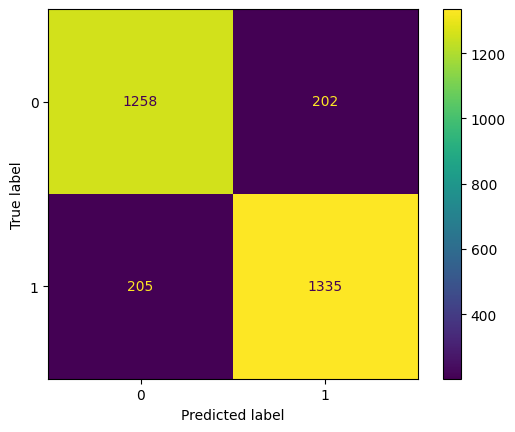

In [25]:
# Cria a matriz de confusão
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();

In [62]:
# Os ajustes foram sendo executados manualmente, os piores resultados foram 0.84 e os melhores 0.86
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo_ajustado = RandomForestClassifier(min_samples_leaf=3,
                                         n_estimators=500,
                                         max_features='log2',
                                         min_samples_split=5,
                                         max_depth = 20)

scores = cross_val_score(modelo_ajustado, X, y, cv=kf, scoring="accuracy")
average_r2 = np.mean(scores)

print(f"Score para cada pedaço:{[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average_r2:.2f}")

modelo_ajustado.fit(X_treino, y_treino)
y_predc = modelo_ajustado.predict(X_teste)


accuracy = accuracy_score(y_teste, y_predc)
print("Accuracy:", accuracy)

R² Score for each fold: [np.float64(0.8603), np.float64(0.8623), np.float64(0.8487), np.float64(0.8603), np.float64(0.858)]
Average R² across 5 folds: 0.86
Accuracy: 0.865


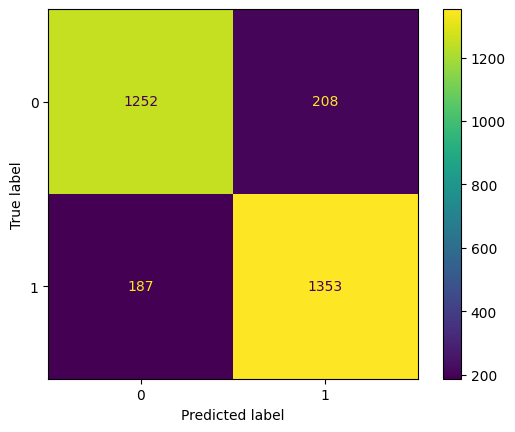

In [61]:
cm = confusion_matrix(y_teste, y_predc)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();

In [24]:
# Calcula a probabilidade de vitoria
probabilities = model.predict_proba(X_test)
indice_vitoria = list(model.classes_).index(1)

# Extraindo a probabilidade de vitória em porcentagem
chances_vitoria = probabilities[:, indice_vitoria] * 100

# Exibindo os resultados
resultados = pd.DataFrame({
    "Resultado real": y_test.values,
    "Chance de vitória (%)": chances_vitoria,
    "Previsão do modelo": model.predict(X_test)
})

print(resultados)

      Resultado real  Chance de vitória (%)  Previsão do modelo
0                  1                   95.0                   1
1                  0                   67.0                   1
2                  0                   30.0                   0
3                  0                   20.0                   0
4                  0                   47.0                   0
...              ...                    ...                 ...
2995               1                   62.0                   1
2996               1                   69.0                   1
2997               0                    1.0                   0
2998               0                   25.0                   0
2999               0                   53.0                   1

[3000 rows x 3 columns]
